# Hafta 7 – Ters Z-Dönüşümü (Inverse Z-Transform)

Bu notebook, **Sinyaller ve Sistemler** dersi kapsamında **ters Z-dönüşümü** konusunu
örnekler ve görseller eşliğinde incelemek için hazırlanmıştır.

## Öğrenme Hedefleri

Bu haftanın sonunda öğrenci aşağıdakileri yapabilmelidir:

- Z-dönüşümünün tersini (inverse Z-transform) kavramsal olarak açıklayabilmek
- Ters Z-dönüşüm için **kısmi kesirlere ayırma**, **güç serisi açılımı** ve **konvolüsyon** yöntemlerini kullanabilmek
- Aynı $X(z)$ ifadesi için **farklı ROC** seçimlerinin farklı $x[n]$ dizileri verdiğini gösterebilmek
- Bir sistem fonksiyonu \(H(z)\) üzerinden **dürtü yanıtı $h[n]$** elde edebilmek

## Hatırlatma: Z-Dönüşümü ve Tersi

Z-dönüşüm tanımı:

$X(z) = \mathcal{Z}\{x[n]\} = \sum_{n=-\infty}^{\infty} x[n] z^{-n}$

Ters Z-dönüşümün genel integralli ifadesi:

$x[n] = \mathcal{Z}^{-1}\{X(z)\} = \frac{1}{2\pi j} \oint_C X(z)\,z^{n-1}\,dz$

Pratikte integrali doğrudan hesaplamak yerine farklı **analitik yöntemler** kullanacağız.

## 1. Z-Düzlemi ve ROC'un Görselleştirilmesi

Bu bölümde kutupları (poles) ve bir örnek ROC (Region of Convergence) bölgesini
**z-düzlemi** üzerinde çizeceğiz.

- Birim çember: $|z| = 1$
- Örnek kutuplar: $z = 0.6$ ve $z = 0.8$
- Örnek ROC: $|z| > 0.8$ (causal örnek)

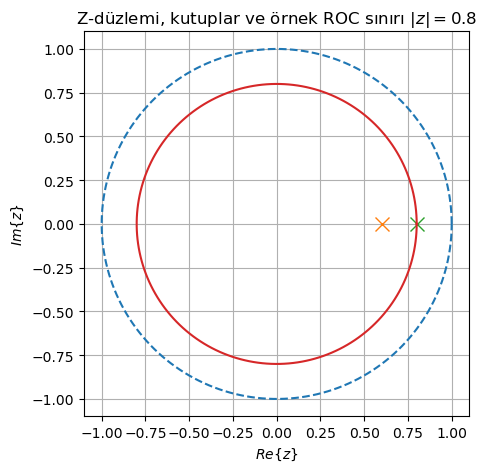

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Birim çember
theta = np.linspace(0, 2*np.pi, 400)
unit_circle_x = np.cos(theta)
unit_circle_y = np.sin(theta)

fig, ax = plt.subplots(figsize=(5, 5))

# Birim çember
ax.plot(unit_circle_x, unit_circle_y, linestyle='--')
ax.set_aspect('equal', 'box')

# Örnek kutuplar
poles = [0.6, 0.8]  # gerçek eksen üzerindeki kutuplar
for p in poles:
    ax.plot(np.real(p), np.imag(p), 'x', markersize=10)

# Örnek ROC: |z| > 0.8 (kabaca dış bölgeyi tarayalım)
roc_r = 0.8
roc_theta = np.linspace(0, 2*np.pi, 200)
roc_x = roc_r * np.cos(roc_theta)
roc_y = roc_r * np.sin(roc_theta)
ax.plot(roc_x, roc_y)

ax.set_xlabel('$Re\{z\}$')
ax.set_ylabel('$Im\{z\}$')
ax.set_title('Z-düzlemi, kutuplar ve örnek ROC sınırı $|z| = 0.8$')
ax.grid(True)
plt.show()

Yukarıdaki şekilde:

- `x` işaretleri kutupları göstermektedir.
- Çizgili çember birim çemberi $(|z|=1)$ göstermektedir.
- $|z| = 0.8$ çemberi, $|z| > 0.8$ ROC bölgesinin **iç sınırıdır**.

### 1.1. İnteraktif: ROC Değiştikçe $x[n]$ Nasıl Değişir?

Aşağıdaki hücrede, tek kutuplu bir sistem için

$X(z) = \frac{1}{1 - a z^{-1}}$

ifadesini kullanıyoruz. ROC seçimlerine göre:

- $|z| > |a|$ ise: $x[n] = a^n u[n]$ (**causal**)
- $|z| < |a|$ ise: $x[n] = -a^n u[-n-1]$ (**anti-causal**)

Slaytırı (slider) ve ROC seçimini değiştirerek sinyalin nasıl değiştiğini gözlemleyebilirsiniz.

ÇALIŞTIRMA 1: NEDENSEL SİNYAL (Kararlı)


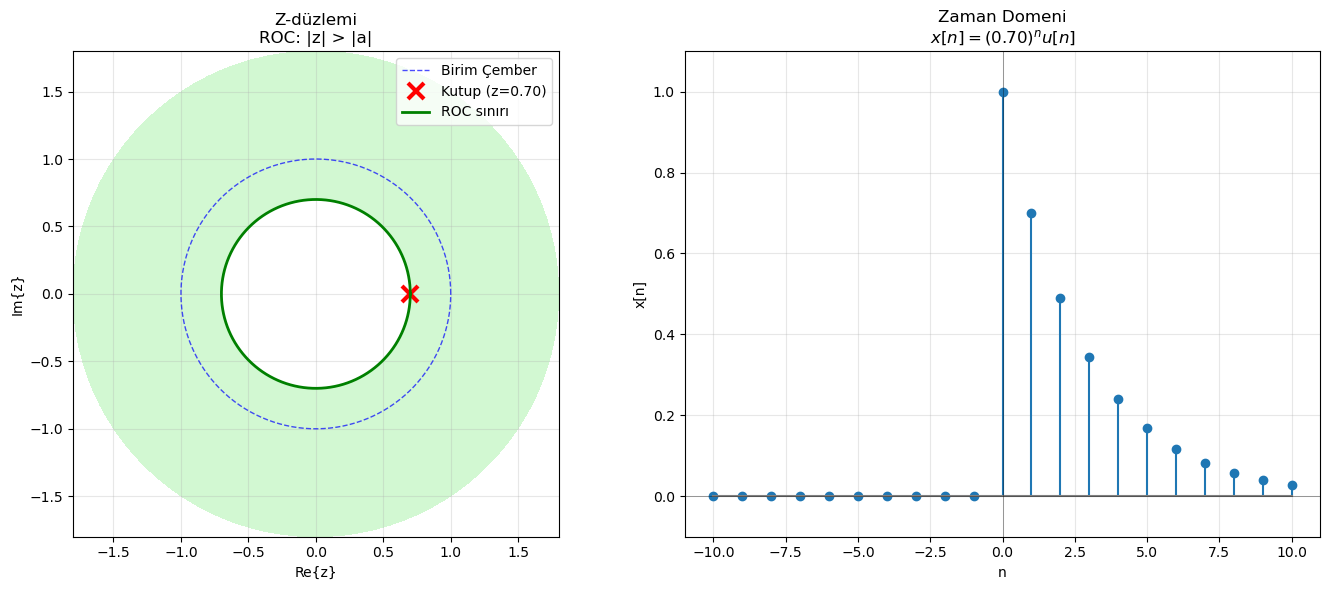

SİNYAL TİPİ: Nedensel (Causal)
KUTUP: z = 0.70
ROC: |z| > |a|
DURUM: KARARLI (ROC birim çemberi içeriyor)

ÇALIŞTIRMA 2: NEDENSEL OLMAYAN SİNYAL


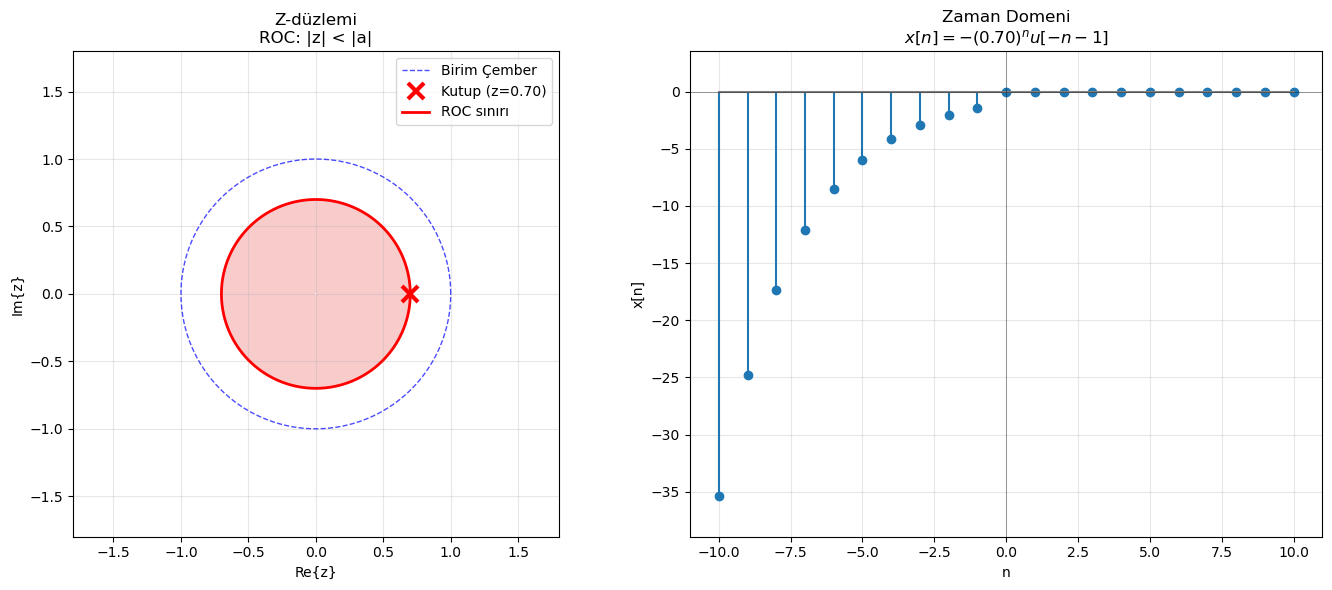

SİNYAL TİPİ: Nedensel Olmayan (Anti-causal)
KUTUP: z = 0.70
ROC: |z| < |a|
DURUM: KARARSIZ (Anti-causal sistemler genellikle kararsızdır)

ÇALIŞTIRMA 3: KARARLI NEDENSEL SİNYAL (Küçük kutup)


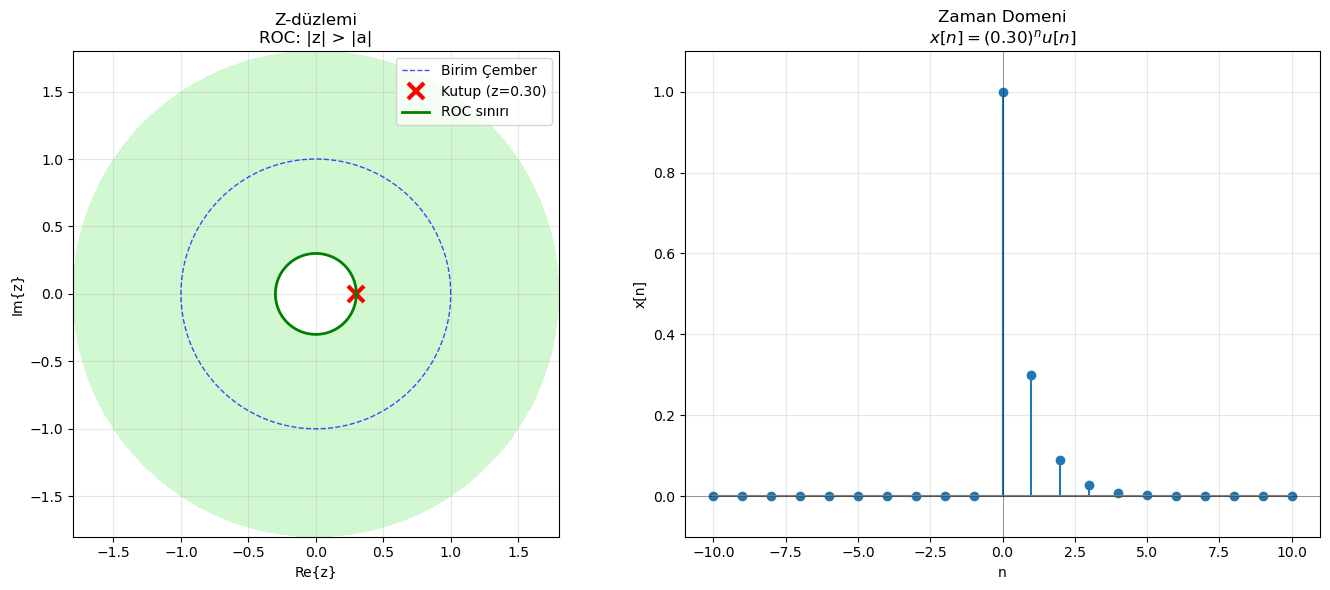

SİNYAL TİPİ: Nedensel (Causal)
KUTUP: z = 0.30
ROC: |z| > |a|
DURUM: KARARLI (ROC birim çemberi içeriyor)

ÇALIŞTIRMA 4: KARARSIZ NEDENSEL SİNYAL (Büyük kutup)


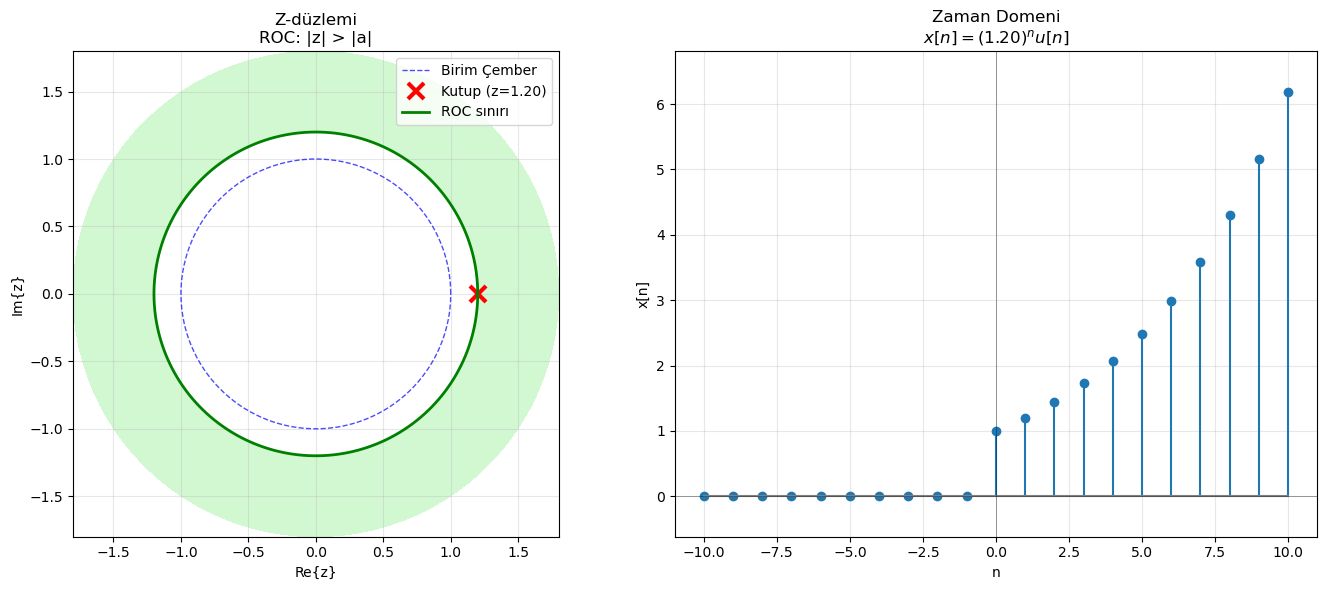

SİNYAL TİPİ: Nedensel (Causal)
KUTUP: z = 1.20
ROC: |z| > |a|
DURUM: KARARSIZ (ROC birim çemberi içermiyor)



In [27]:
import numpy as np
import matplotlib.pyplot as plt

def plot_signal_and_roc(a=0.7, roc_type='|z| > |a| (causal)'):
    # Zaman domeni sinyali
    n = np.arange(-10, 11)  # -10'dan 10'a kadar
    
    if roc_type.startswith('|z| >'):
        # causal: x[n] = a^n u[n]
        x = np.zeros_like(n, dtype=float)
        for i in range(len(n)):
            if n[i] >= 0:
                x[i] = a ** n[i]
        signal_type = "Nedensel (Causal)"
        roc_label = 'ROC: |z| > |a|'
        formula = r'$x[n] = (' + f'{a:.2f}' + r')^n u[n]$'
    else:
        # anti-causal: x[n] = -a^n u[-n-1]
        x = np.zeros_like(n, dtype=float)
        for i in range(len(n)):
            if n[i] <= -1:  # n = -1, -2, -3, ... için
                x[i] = -a ** n[i]
        signal_type = "Nedensel Olmayan (Anti-causal)"
        roc_label = 'ROC: |z| < |a|'
        formula = r'$x[n] = -(' + f'{a:.2f}' + r')^n u[-n-1]$'

    # Z-düzlemi plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # 1. Z-düzlemi grafiği
    theta = np.linspace(0, 2*np.pi, 400)
    
    # Birim çember
    ax1.plot(np.cos(theta), np.sin(theta), 'b--', alpha=0.7, linewidth=1, label='Birim Çember')
    
    # Kutup
    ax1.plot(a, 0, 'rx', markersize=12, markeredgewidth=3, label=f'Kutup (z={a:.2f})')
    
    # ROC bölgesi
    roc_r = abs(a)
    
    if roc_type.startswith('|z| >'):
        # |z| > |a| için: kutup yarıçapının DIŞINDAKİ tüm bölge
        # Dış daireyi çiz
        outer_circle_x = roc_r * np.cos(theta)
        outer_circle_y = roc_r * np.sin(theta)
        ax1.plot(outer_circle_x, outer_circle_y, 'g-', linewidth=2, label='ROC sınırı')
        
        # Dış bölgeyi tarama (kutup dışındaki tüm alan)
        # Bunun için polar koordinatlarda r > roc_r olan bölge
        r_outer = np.linspace(roc_r, 1.8, 50)
        theta_outer = np.linspace(0, 2*np.pi, 100)
        R, THETA = np.meshgrid(r_outer, theta_outer)
        X = R * np.cos(THETA)
        Y = R * np.sin(THETA)
        ax1.contourf(X, Y, np.ones_like(X), levels=[0.5, 1], colors=['lightgreen'], alpha=0.4)
        
    else:
        # |z| < |a| için: kutup yarıçapının İÇİNDEKİ bölge (0 hariç)
        # İç daireyi çiz
        inner_circle_x = roc_r * np.cos(theta)
        inner_circle_y = roc_r * np.sin(theta)
        ax1.plot(inner_circle_x, inner_circle_y, 'r-', linewidth=2, label='ROC sınırı')
        
        # İç bölgeyi tarama (kutup içindeki alan, 0 dahil değil)
        r_inner = np.linspace(0.01, roc_r, 50)  # 0'dan kaçınmak için 0.01
        theta_inner = np.linspace(0, 2*np.pi, 100)
        R, THETA = np.meshgrid(r_inner, theta_inner)
        X = R * np.cos(THETA)
        Y = R * np.sin(THETA)
        ax1.contourf(X, Y, np.ones_like(X), levels=[0.5, 1], colors=['lightcoral'], alpha=0.4)
    
    ax1.set_aspect('equal', 'box')
    ax1.set_xlabel('Re{z}')
    ax1.set_ylabel('Im{z}')
    ax1.set_title(f'Z-düzlemi\n{roc_label}')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    ax1.set_xlim(-1.8, 1.8)
    ax1.set_ylim(-1.8, 1.8)

    # 2. Zaman domeni grafiği
    ax2.stem(n, x, basefmt='gray')
    ax2.set_xlabel('n')
    ax2.set_ylabel('x[n]')
    ax2.set_title(f'Zaman Domeni\n{formula}')
    ax2.grid(True, alpha=0.3)
    
    # Eksenleri ayarla
    y_min, y_max = np.min(x), np.max(x)
    y_padding = 0.1 * (y_max - y_min) if y_max != y_min else 0.5
    ax2.set_ylim(y_min - y_padding, y_max + y_padding)
    
    # Sıfır çizgisi
    ax2.axhline(0, color='black', linewidth=0.5, alpha=0.5)
    ax2.axvline(0, color='black', linewidth=0.5, alpha=0.5)

    plt.tight_layout()
    plt.show()
    
    # Bilgilendirme
    print("=" * 70)
    print(f"SİNYAL TİPİ: {signal_type}")
    print(f"KUTUP: z = {a:.2f}")
    print(f"{roc_label}")
    
    if roc_type.startswith('|z| >'):
        if roc_r < 1:
            print("DURUM: KARARLI (ROC birim çemberi içeriyor)")
        else:
            print("DURUM: KARARSIZ (ROC birim çemberi içermiyor)")
    else:
        print("DURUM: KARARSIZ (Anti-causal sistemler genellikle kararsızdır)")
    print()

# Test çalıştırmaları
print("ÇALIŞTIRMA 1: NEDENSEL SİNYAL (Kararlı)")
plot_signal_and_roc(a=0.7, roc_type='|z| > |a| (causal)')

print("ÇALIŞTIRMA 2: NEDENSEL OLMAYAN SİNYAL")
plot_signal_and_roc(a=0.7, roc_type='|z| < |a| (anti-causal)')

print("ÇALIŞTIRMA 3: KARARLI NEDENSEL SİNYAL (Küçük kutup)")
plot_signal_and_roc(a=0.3, roc_type='|z| > |a| (causal)')

print("ÇALIŞTIRMA 4: KARARSIZ NEDENSEL SİNYAL (Büyük kutup)")
plot_signal_and_roc(a=1.2, roc_type='|z| > |a| (causal)')

## 2. Ters Z-Dönüşüm Yöntemi 1: Kısmi Kesirlere Ayırma

Birçok rasyonel $X(z)$ ifadesi aşağıdaki forma getirilebilir:

$$X(z) = \sum_{k=1}^{K} \frac{A_k}{1 - a_k z^{-1}}$$

Causal bir sistem/sinyal için ters Z-dönüşümü:

$$x[n] = \sum_{k=1}^{K} A_k a_k^n u[n]$$

Aşağıdaki örnekte SymPy kullanarak kısmi kesirlere ayırmayı gösteriyoruz.

In [28]:
import sympy as sp

z = sp.symbols('z')
# Aşağıdaki denklemi değiştirerek deneyiniz...
X = z**2 / ((z - 0.5)*(z - 0.8))

sp.apart(X, z)

1.0 - 0.833333333333333/(1.0*z - 0.5) + 2.13333333333333/(1.0*z - 0.8)

SymPy'nin ürettiği ifade, $X(z)$ 'yi basit rasyonel parçalara ayırır. Bu parçaları
$\frac{A}{1 - a z^{-1}}$ formuna dönüştürerek $x[n]$ ifadesini elde edebiliriz.

> Alıştırma: Aşağıdaki $X(z)$ ifadesini kısmi kesirlere ayırıp causal $x[n]$'i bulunuz.

$$X(z) = \frac{z}{(z - 0.3)(z - 0.9)}$$

## 3. Ters Z-Dönüşüm Yöntemi 2: Güç Serisi Açılımı

Temel geometrik seri:

$$\frac{1}{1 - a z^{-1}} = \sum_{n=0}^{\infty} a^n z^{-n}, \quad |z| > |a|$$

Bu, zaman domeninde:

$x[n] = a^n u[n]$

şeklindedir. Aynı rasyonel ifade, farklı ROC için **anti-causal** bir dizi de üretebilir:

$$\frac{1}{1 - a z^{-1}} = -\sum_{n=-\infty}^{-1} a^n z^{-n}, \quad |z| < |a|$$

Aşağıda $a = 0.8$ için causal ve anti-causal dizileri sayısal olarak oluşturalım.

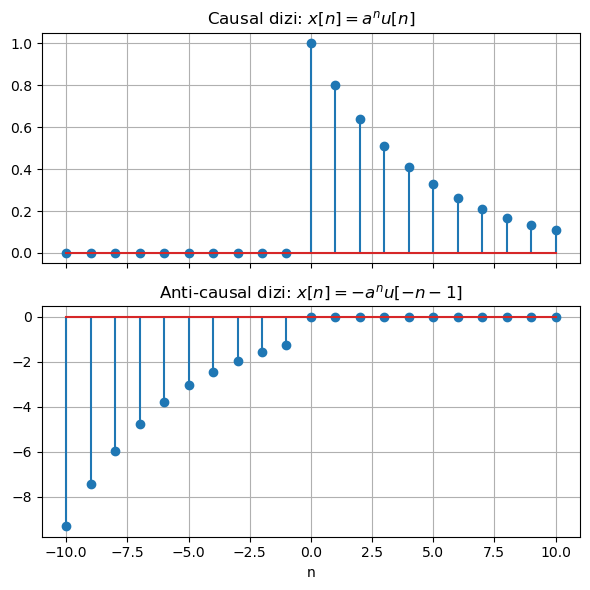

In [29]:
import numpy as np
import matplotlib.pyplot as plt

a = 0.8
n = np.arange(-10, 11)

x_causal = (a**n) * (n >= 0)
x_anti = -(a**n) * (n <= -1)

fig, axes = plt.subplots(2, 1, figsize=(6, 6), sharex=True)

axes[0].stem(n, x_causal)
axes[0].set_title('Causal dizi: $x[n] = a^n u[n]$')
axes[0].grid(True)

axes[1].stem(n, x_anti)
axes[1].set_title('Anti-causal dizi: $x[n] = -a^n u[-n-1]$')
axes[1].grid(True)

axes[1].set_xlabel('n')
plt.tight_layout()
plt.show()

## 4. Ters Z-Dönüşüm Yöntemi 3: Konvolüsyon

Bir sistem fonksiyonu aşağıdaki gibi çarpım halinde yazılabiliyorsa:

$H(z) = H_1(z)\,H_2(z)$

zaman domeninde dürtü yanıtları arasında

$h[n] = h_1[n] * h_2[n]$

ilişkisi vardır.

Örnek bir sistem:

$$H(z) = \frac{1}{(1 - 0.4 z^{-1})(1 - 0.8 z^{-1})}$$

Bunu

$$
H_1(z) = \frac{1}{1 - 0.4 z^{-1}}, \quad
H_2(z) = \frac{1}{1 - 0.8 z^{-1}}
$$

şeklinde ayırabiliriz. Causal kabul edersek:

$$
h_1[n] = 0.4^n u[n], \quad
h_2[n] = 0.8^n u[n]
$$

ve

$$
h[n] = h_1[n] * h_2[n]
$$

olur.

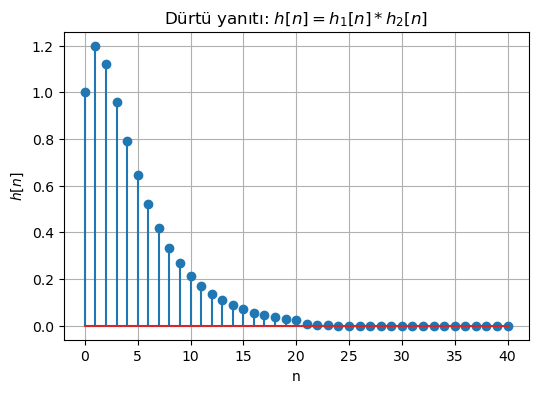

In [30]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(0, 21)
h1 = (0.4**n)
h2 = (0.8**n)

h = np.convolve(h1, h2)
n_h = np.arange(0, len(h))

plt.figure(figsize=(6,4))
plt.stem(n_h, h)
plt.xlabel('n')
plt.ylabel('$h[n]$')
plt.title('Dürtü yanıtı: $h[n] = h_1[n] * h_2[n]$')
plt.grid(True)
plt.show()

## 5. Önemli Z-Dönüşüm Tablosu Çiftleri

Aşağıdaki temel çiftler, ters Z-dönüşümü yaparken **bilinmesi gereken** ifadelerdir.

$$
\begin{array}{|c|c|c|}
\hline
x[n] & X(z) & \text{ROC} \\
\hline
\delta[n] & 1 & 0 < |z| < \infty \\
\hline
u[n] & \frac{1}{1 - z^{-1}} & |z| > 1 \\
\hline
a^n u[n] & \frac{1}{1 - a z^{-1}} & |z| > |a| \\
\hline
-a^n u[-n-1] & \frac{1}{1 - a z^{-1}} & |z| < |a| \\
\hline
a^{n-k} u[n-k] & z^{-k}\,\frac{1}{1 - a z^{-1}} & |z| > |a| \\
\hline
r^n \cos(\Omega_0 n)\,u[n] & \frac{1 - r\cos(\Omega_0) z^{-1}}{1 - 2 r\cos(\Omega_0) z^{-1} + r^2 z^{-2}} & |z| > r \\
\hline
\text{Sonlu diziler} & \sum_{n=0}^{N-1} x[n] z^{-n} & 0 < |z| < \infty \\
\hline
\hline
n\,x[n] & -z\,\dfrac{dX(z)}{dz} & X(z)\text{'nin türevine bağlıdır} \\
\hline
\end{array}
$$

> Not: Birçok tablo girdisi, temel
> $\displaystyle \frac{1}{1 - a z^{-1}}$
> ifadesi ve **zaman kaydırma** özelliğinden türetilebilir.

## 6. ROC'un Sonuca Etkisini Gösteren Örnek

Aşağıdaki örnekte

$$
X(z) = \frac{1}{1 - 0.7 z^{-1}}
$$

için iki farklı ROC seçip elde ettiğimiz zaman domeni sinyallerini karşılaştırıyoruz.

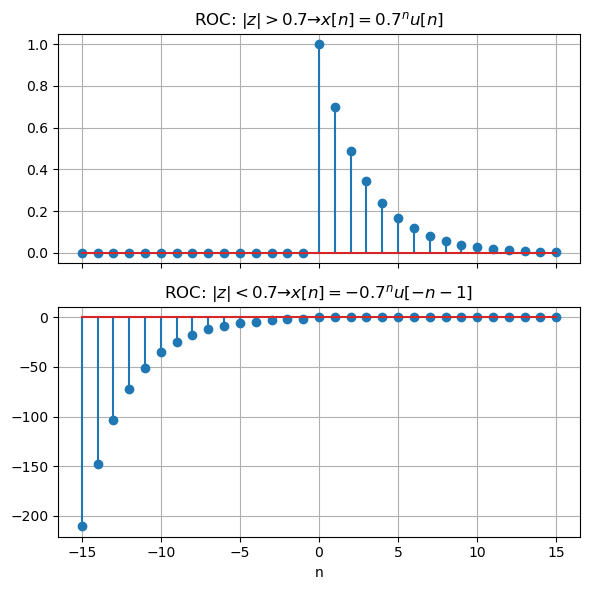

In [31]:
import numpy as np
import matplotlib.pyplot as plt

a = 0.7
n = np.arange(-15, 16)

x_causal = (a**n) * (n >= 0)
x_anti = -(a**n) * (n <= -1)

fig, axes = plt.subplots(2, 1, figsize=(6, 6), sharex=True)

axes[0].stem(n, x_causal)
axes[0].set_title('ROC: $|z| > 0.7  →  x[n] = 0.7^n u[n]$')
axes[0].grid(True)

axes[1].stem(n, x_anti)
axes[1].set_title('ROC: $|z| < 0.7  →  x[n] = -0.7^n u[-n-1]$')
axes[1].grid(True)

axes[1].set_xlabel('n')
plt.tight_layout()
plt.show()

## 7. Mini Quiz (Çözümlü)

### Soru 1

$$
X(z) = \frac{z}{z - 0.5}
$$

için

- (a) ROC: $|z| > 0.5$ iken $x[n]$'i bulunuz.
- (b) ROC: $|z| < 0.5$ iken $x[n]$'i bulunuz.

**Çözüm (a):**

$$
X(z) = \frac{z}{z - 0.5} = \frac{1}{1 - 0.5 z^{-1}}, \quad |z| > 0.5
$$

Bu, tabloda $a = 0.5$ için $a^n u[n]$'e karşılık gelir. Dolayısıyla:

$$
x[n] = 0.5^n u[n]
$$

**Çözüm (b):**

Aynı ifade için ROC: $|z| < 0.5$ seçersek:

$$
x[n] = -0.5^n u[-n-1]
$$

olur. Burada dizi **anti-causal**'dir.

### Soru 2

$$
H(z) = \frac{1 - 0.5 z^{-1}}{1 - 0.9 z^{-1}}
$$

causal bir sistem için \$h[n]$'i bulunuz.

**İpucu:** Pay ve paydayı bilinen tablolar yardımıyla ayırmaya çalışın.

**Çözüm:**

Önce şu şekilde yazalım:

$
H(z) = (1 - 0.5 z^{-1}) \cdot \frac{1}{1 - 0.9 z^{-1}}
$

Tablodan:

$
\frac{1}{1 - 0.9 z^{-1}} \longleftrightarrow 0.9^n u[n]
$

Ayrıca $1 - 0.5 z^{-1}$ terimi zaman domeninde

$
h_0[n] = \delta[n] - 0.5 \delta[n-1]
$

şeklinde düşünülebilir. Dolayısıyla

$
h[n] = h_0[n] * 0.9^n u[n]
$

Konvolüsyondan

$
h[n] = 0.9^n u[n] - 0.5 \cdot 0.9^{n-1} u[n-1]
$

elde edilir.

## 8. Ödev / Alıştırmalar (Çözümsüz)

1. $$
   X(z) = \frac{z^2}{(z-0.3)(z-0.7)}
   $$
   ifadesi için ROC: $|z| > 0.7$ iken ters Z-dönüşümünü bulunuz.

2. $$
   X(z) = \frac{1}{1 - 1.2 z^{-1}}
   $$
   ifadesi için, sistemin **kararlı** olabilmesi için hangi ROC seçilmelidir?
   Bu ROC altında $x[n]$ nedir? (İpucu: BIBO kararlılık ve birim çember ilişkisi)

3. $$
   H(z) = \frac{1}{(1 - 0.5 z^{-1})^2}
   $$
   causal sistem için $h[n]$'i bulunuz. (İpucu: Üstel dizinin türevi)

4. Aşağıdaki dizinin Z-dönüşümünü bulun ve ROC'u belirleyin:

   $$
   x[n] = \begin{cases}
   1, & 0 \le n \le 3 \\
   0, & \text{diğer}
   \end{cases}
   $$

5. Aynı $X(z)$ ifadesi için iki farklı ROC verildiğinde, elde edilen zaman domeni
   dizilerinin causal/anti-causal olup olmadığını tartışın.